# Behavior cloning for a delivery robot on an 8x8 grid

A robot has to pick up a package and deliver it on a small grid map, and we only get expert demonstrations to learn from. I trained a ResNet with FiLM conditioning to predict the next actions, used rotations and flips of the grid as augmentation and added a wrapper that stops the robot from going back and forth. Success rate on the 1600 test scenarios was 0.994.

# Robot Delivery Academy: Preparatory Program

## 1. Problem Description

Welcome to the **Robot Delivery Academy**, the preparatory program for the Robot Training task.

You are working with a small delivery robot on an `8 x 8` city map. In each episode, the robot starts somewhere on the map, picks up a package from one depot, and delivers it to another depot. Some cells are blocked, and every map is slightly different.

For a human programmer, this kind of task may look easy: inspect the map, find a path, pick up the package, deliver it. But the goal here is different. We want to check whether an AI model can learn this behavior from examples instead of being given the full hand-written strategy.

The training principle is supervised learning. We prepare many examples of the form:

```text
observation -> action
```

The model sees what action was taken in each situation and tries to learn the pattern. Later, it must act on new scenarios where the answers are not provided.

### Your Mission

Train a model that can:

1. Learn from provided demonstrations.
2. Predict a useful next action from the current observation.
3. Run for a complete episode and deliver the package.
4. Generalize to validation and test scenarios that were not shown as demonstrations.

### The Challenge

You are given a deliberately small demonstration budget. The interesting question is not whether the task can be solved by a search algorithm, but whether you can train a model that learns enough from limited examples.

A single wrong action can move the robot into states that were rare in the demonstrations, so high action accuracy does not always mean high episode success.


## 2. Download the data

This task's data (three `.pkl` files) lives in the shared **`IOAI-2026/RobotDelivery`** Drive folder. The cell below downloads it into a local `data/` folder — no sign-in or setup, just run it.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import numpy as np
import pandas as pd

Mounted at /content/drive


## 3. Understanding the Task Simulator

For this preparatory task, we also provide a small simulator. It is mainly here to make the task easier to understand: you can use it to inspect scenario conditions, replay demonstration trajectories, and visualize the solutions produced by your model.

The task is a small grid delivery problem.

- The grid size is `8 x 8`.
- There are six depot cells: `A`, `B`, `C`, `D`, `E`, `F`.
- One depot contains the package.
- Another depot is the destination.
- The robot must move to the package, pick it up, move to the destination, and drop it off.
- Walls block movement.

The simulator is included directly in this notebook so it works as a single Google Colab file. It is used to show examples and to check complete episodes after training. The visual helper below can also save and display animated GIFs.


In [ ]:
import json
import pickle
import random
import zipfile
from collections import Counter
from pathlib import Path
from typing import Any

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from IPython.display import Image as NotebookImage, display
from PIL import Image as PILImage, ImageDraw
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

GRID_SIZE = 8
N_DEPOTS = 6
MAX_STEPS = 120
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ACTION_NAMES = {
    0: "south",
    1: "north",
    2: "east",
    3: "west",
    4: "pickup",
    5: "dropoff",
}

ACTION_DELTAS = {
    0: (1, 0),
    1: (-1, 0),
    2: (0, 1),
    3: (0, -1),
}

DEPOT_NAMES = ["A", "B", "C", "D", "E", "F"]

#print("data dir:", DATA_DIR)
print("device:", DEVICE)
DATA_DIR = Path("/content/drive/MyDrive/")

device: cuda


In [ ]:
class DeliverySimulator8x8:
    """Run one 8x8 delivery episode."""

    def reset(self, scenario: dict[str, Any]) -> tuple[int, int, int, int]:
        """Start a scenario and return the compact state."""
        self.step_count = 0
        self.carrying = False
        self.walls = {tuple(cell) for cell in scenario["walls"]}
        self.depots = [tuple(cell) for cell in scenario["depots"]]
        self.agent_pos = tuple(scenario["agent_pos"])
        self.package_location = int(scenario["package_location"])
        self.destination = int(scenario["destination"])
        return self.state()

    def state(self) -> tuple[int, int, int, int]:
        """Return row, column, package field, and destination."""
        package_field = N_DEPOTS if self.carrying else self.package_location
        return int(self.agent_pos[0]), int(self.agent_pos[1]), int(package_field), int(self.destination)

    def can_enter(self, row: int, col: int) -> bool:
        """Check whether the robot can occupy a cell."""
        return 0 <= row < GRID_SIZE and 0 <= col < GRID_SIZE and (row, col) not in self.walls

    def valid_action_mask(self) -> np.ndarray:
        """Return the currently valid actions."""
        row, col, _, destination = self.state()
        mask = np.zeros(6, dtype=bool)
        for action, (dr, dc) in ACTION_DELTAS.items():
            mask[action] = self.can_enter(row + dr, col + dc)
        mask[4] = (not self.carrying) and self.agent_pos == self.depots[self.package_location]
        mask[5] = self.carrying and self.agent_pos == self.depots[destination]
        return mask

    def observation(self) -> dict[str, Any]:
        """Build the model observation for the current state."""
        row, col, package_field, destination = self.state()
        carrying = package_field == N_DEPOTS
        dest_row, dest_col = self.depots[destination]
        target_row, target_col = (dest_row, dest_col) if carrying else self.depots[package_field]

        grid = np.zeros((6, GRID_SIZE, GRID_SIZE), dtype=np.float32)
        for wr, wc in self.walls:
            grid[0, wr, wc] = 1.0
        for dr, dc in self.depots:
            grid[1, dr, dc] = 1.0
        grid[2, row, col] = 1.0
        if not carrying:
            pr, pc = self.depots[package_field]
            grid[3, pr, pc] = 1.0
        grid[4, dest_row, dest_col] = 1.0
        grid[5, :, :] = float(carrying)

        blocked_moves = [float(not self.can_enter(row + dr, col + dc)) for dr, dc in ACTION_DELTAS.values()]
        vector = np.array(
            [
                row / (GRID_SIZE - 1),
                col / (GRID_SIZE - 1),
                package_field / N_DEPOTS,
                destination / (N_DEPOTS - 1),
                float(carrying),
                target_row / (GRID_SIZE - 1),
                target_col / (GRID_SIZE - 1),
                (target_row - row) / (GRID_SIZE - 1),
                (target_col - col) / (GRID_SIZE - 1),
                *blocked_moves,
            ],
            dtype=np.float32,
        )
        return {"grid": grid, "vector": vector, "action_mask": self.valid_action_mask(), "state": self.state()}

    def step(self, action: int) -> tuple[tuple[int, int, int, int], bool, bool, dict[str, Any]]:
        """Apply one action and report episode status."""
        action = int(action)
        done = False
        info = {"invalid_pickup_or_dropoff": False}

        if action in ACTION_DELTAS:
            dr, dc = ACTION_DELTAS[action]
            row, col = self.agent_pos[0] + dr, self.agent_pos[1] + dc
            if self.can_enter(row, col):
                self.agent_pos = (row, col)
        elif action == 4 and (not self.carrying) and self.agent_pos == self.depots[self.package_location]:
            self.carrying = True
        elif action == 5 and self.carrying and self.agent_pos == self.depots[self.destination]:
            done = True
            self.carrying = False
            self.package_location = self.destination
        elif action in (4, 5):
            info["invalid_pickup_or_dropoff"] = True
        else:
            raise ValueError(f"unknown action: {action}")

        self.step_count += 1
        return self.state(), done, self.step_count >= MAX_STEPS and not done, info

    def render(self) -> str:
        """Return an ASCII rendering of the current grid."""
        grid = [["." for _ in range(GRID_SIZE)] for _ in range(GRID_SIZE)]
        for row, col in self.walls:
            grid[row][col] = "#"
        for i, (row, col) in enumerate(self.depots):
            grid[row][col] = DEPOT_NAMES[i]

        agent_row, agent_col = self.agent_pos
        grid[agent_row][agent_col] = "T*" if self.carrying else "T"
        rows = [" ".join(f"{cell:>2}" for cell in row) for row in grid]
        package_name = "in taxi" if self.carrying else DEPOT_NAMES[self.package_location]
        rows.append(f"package={package_name}, destination={DEPOT_NAMES[self.destination]}")
        return "\n".join(rows)


## 4. Dataset

### 4.1 Provided Training Data

You are provided with expert demonstrations saved in `data/train_demos.pkl`.

Each trajectory contains observations and expert actions from one successful delivery episode.

**Data Format:**

```python
{
    "trajectories": [
        {
            "layout_id": str,
            "episode_seed": int,
            "scenario": dict,
            "observations": [
                {
                    "grid": np.array,       # shape: (6, 8, 8)
                    "vector": np.array,     # shape: (13,)
                    "action_mask": np.array,# shape: (6,)
                    "state": tuple
                },
                ...
            ],
            "actions": [int, ...],       # action IDs 0-5
            "success": bool,
            "num_steps": int
        },
        ...
    ]
}
```

### 4.2 Validation and Test Scenarios

You are also provided with:

- `data/valid_scenarios.pkl`
- `data/test_scenarios.pkl`

These files contain delivery scenarios without expert action labels. They are used to run your trained model and check complete-episode success.


In [ ]:
DATA_DIR = Path('/content/drive/MyDrive/')

with (DATA_DIR / "train_demos.pkl").open("rb") as f:
    train_data = pickle.load(f)

with (DATA_DIR / "valid_scenarios.pkl").open("rb") as f:
    valid_scenarios = pickle.load(f)

with (DATA_DIR / "test_scenarios.pkl").open("rb") as f:
    test_scenarios = pickle.load(f)

train_trajectories = train_data["trajectories"]
steps = [t["num_steps"] for t in train_trajectories]

print("Loaded data")
print("  training demonstrations:", len(train_trajectories))
print("  validation scenarios:", len(valid_scenarios))
print("  test scenarios:", len(test_scenarios))
print("  training state-action samples:", sum(steps))
print("  average demonstration length:", f"{np.mean(steps):.2f}")
print("  expert success rate:", f"{100 * np.mean([t['success'] for t in train_trajectories]):.1f}%")


Loaded data
  training demonstrations: 400
  validation scenarios: 200
  test scenarios: 1600
  training state-action samples: 5327
  average demonstration length: 13.32
  expert success rate: 100.0%


Example trajectory
  layout_id: train_0000
  episode_seed: 100000
  num_steps: 23
  actions: ['north', 'north', 'north', 'east', 'east', 'east', 'east', 'east', 'pickup', 'south', 'west', 'south', 'south', 'south', 'south', 'south', 'west', 'west', 'west', 'west', 'west', 'west', 'dropoff']

Observation
  grid shape: (6, 8, 8)
  vector shape: (13,)
  valid actions: ['south', 'north', 'east']

Initial frame
 .  .  .  .  .  .  .  A
 .  #  .  .  E  #  D  .
 .  .  .  .  .  .  .  #
 .  #  T  .  .  #  .  .
 F  .  .  #  #  .  .  .
 .  .  .  .  .  #  .  .
 B  .  .  .  .  .  .  .
 .  .  .  .  .  .  .  .
package=A, destination=B

Animated example


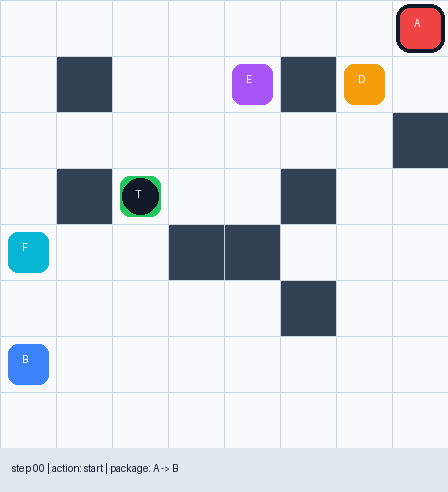

In [ ]:
example = train_trajectories[0]
print("Example trajectory")
print("  layout_id:", example["layout_id"])
print("  episode_seed:", example["episode_seed"])
print("  num_steps:", example["num_steps"])
print("  actions:", [ACTION_NAMES[a] for a in example["actions"]])

obs0 = example["observations"][0]
print("\nObservation")
print("  grid shape:", obs0["grid"].shape)
print("  vector shape:", obs0["vector"].shape)
print("  valid actions:", [ACTION_NAMES[i] for i, ok in enumerate(obs0["action_mask"]) if ok])

simulator = DeliverySimulator8x8()
simulator.reset(example["scenario"])
print("\nInitial frame")
print(simulator.render())

print("\nAnimated example")
show_episode_gif(example["scenario"], example["actions"], path="expert_demo.gif")



## 5. Task

### 5.1 Objective

Train a behavioral cloning action model that:

1. Takes the current observation as input.
2. Predicts the expert's next action.
3. Runs step by step in a full delivery episode.
4. Achieves high success rate on validation and test scenarios.

### 5.2 Input and Output

**Input observation:**

- `grid`: `6 x 8 x 8` tensor with walls, depots, robot position, package position, destination, and carrying flag.
- `vector`: 13 numerical features with normalized position and target information.
- `action_mask`: 6 binary values showing which actions are currently valid.

**Output action:**

A single integer from `0` to `5`:

| id | action |
|---:|---|
| 0 | south |
| 1 | north |
| 2 | east |
| 3 | west |
| 4 | pickup |
| 5 | dropoff |

### 5.3 Training Approach

Behavioral cloning is supervised learning:

1. Extract `(observation, expert_action)` pairs from demonstrations.
2. Train a neural network classifier.
3. Use cross-entropy loss between predicted action logits and expert actions.
4. Run the trained model in complete episodes.

### 5.4 Improving Beyond the Baseline

The baseline below is intentionally simple. Better solutions may come from better input representation, a model that matches the structure of the task, stronger training, and careful analysis of failed episodes.


## 7. Scoring

### 7.1 Evaluation Metric

**Success Rate (SR):**

```text
SR = (# successful delivery episodes) / (# total episodes)
```

An episode is successful if the package is delivered to the destination within the step limit.

### 7.2 Diagnostics

The notebook also reports:

- `avg_steps`: average number of steps used per episode.
- `avg_invalid_pickup_or_dropoff`: average number of invalid pickup/dropoff attempts.

These diagnostics are not a replacement for success rate, but they help debug model behavior.


### 8.1 Create Supervised Training Samples


#||AUGS||

In [ ]:
from tqdm import tqdm
M = 7
MAPS = [
    (lambda r, c: (r, c),         {0:0, 1:1, 2:2, 3:3, 4:4, 5:5}),  # identity
    (lambda r, c: (c, M - r),     {0:3, 1:2, 2:0, 3:1, 4:4, 5:5}),  # rot90
    (lambda r, c: (M - r, M - c), {0:1, 1:0, 2:3, 3:2, 4:4, 5:5}),  # rot180
    (lambda r, c: (M - c, r),     {0:2, 1:3, 2:1, 3:0, 4:4, 5:5}),  # rot270
    (lambda r, c: (M - r, c),     {0:1, 1:0, 2:2, 3:3, 4:4, 5:5}),  # flip vertical
    (lambda r, c: (r, M - c),     {0:0, 1:1, 2:3, 3:2, 4:4, 5:5}),  # flip horizontal
    (lambda r, c: (c, r),         {0:2, 1:3, 2:0, 3:1, 4:4, 5:5}),  # transpose
]

def transform_scenario(scn, fn):
    out = dict(scn)
    out["walls"]     = [list(fn(*w)) for w in scn["walls"]]
    out["depots"]    = [list(fn(*d)) for d in scn["depots"]]
    out["agent_pos"] = list(fn(*scn["agent_pos"]))
    return out

aug_trajectories = []
sim = DeliverySimulator8x8()
for tr in tqdm(train_trajectories):
    for fn, perm in MAPS:
      scenario = transform_scenario(tr['scenario'], fn)
      acts = [perm[int(a)] for a in tr['actions']]
      sim.reset(scenario)
      obs = []
      for a in acts:
        obs.append(sim.observation())
        sim.step(a)
      aug_trajectories.append({"observations": obs, "actions": acts})

100%|██████████| 400/400 [00:01<00:00, 327.43it/s]


#||END AUGS||

In [ ]:
PAD = -100

class DeliveryDemoDataset(Dataset):
    """Store demonstration steps as supervised examples."""

    def __init__(self, trajectories):
        """Collect all observation-action pairs."""
        self.dataset = trajectories
        self.trajs = [(i, t)
                      for i, tr in enumerate(trajectories)
                      for t in range(len(tr['actions']))]
        self.K = 2

    def __len__(self):
        """Return the number of supervised examples."""
        return len(self.trajs)

    def __getitem__(self, idx):
        train_ex, action_idx = self.trajs[idx]
        row = self.dataset[train_ex]['observations'][action_idx]
        grid = row['grid']
        vec = row['vector']
        action_mask = row['action_mask']
        actions = self.dataset[train_ex]['actions']
        response_next_k = torch.tensor([int(actions[action_idx+j]) if action_idx+j<len(actions) else PAD for
                           j in range(self.K)]) # answers to next k moves

        return (
            torch.tensor(grid, dtype=torch.float32),
            torch.tensor(vec, dtype=torch.float32),
            torch.tensor(action_mask, dtype=torch.float32),
            response_next_k
        )

train_dataset = DeliveryDemoDataset(aug_trajectories)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, drop_last=True)


In [ ]:
import torch.nn.functional as F

class ResBlock(nn.Module):
  def __init__(self, ch, vec_dim):
    super(ResBlock, self).__init__()

    self.conv1 = nn.Conv2d(ch, ch, 3, padding=1, bias=False)
    self.bn1 = nn.BatchNorm2d(ch)
    self.conv2 = nn.Conv2d(ch, ch, 3, padding=1, bias=False)
    self.bn2 = nn.BatchNorm2d(ch)
    self.film = FilmLayer(vec_dim, ch)

  def forward(self, X, vec):
    h = F.relu(self.bn1(self.conv1(X)))
    h = self.film(self.bn2(self.conv2(h)), vec)
    return F.relu( X + h )

class FilmLayer(nn.Module):
  def __init__(self, vec_dim, channels):
    super(FilmLayer, self).__init__()
    ## always gamma*x + beta
    self.channels = channels
    self.lin = nn.Linear(vec_dim, 2*channels)
    nn.init.normal_(self.lin.weight, std=0.05)
    nn.init.normal_(self.lin.bias, std=0.05)

  def forward(self, X, vec):
    ## X is always [B, channels, H, W] and (gamma, beta) are [B, channels]
    unif = self.lin(vec)
    gamma, beta = unif[:, :self.channels], unif[:, self.channels:]

    gamma = (1.0 + gamma).unsqueeze(-1).unsqueeze(-1) # Start at gamma=1, beta=0 for better flow of grads and better backpropo results
    beta = beta.unsqueeze(-1).unsqueeze(-1)

    return gamma * X + beta

## ok so firstly so we start with X = [B, 6, 8, 8] and the vec = [13]
## we encode the X as well as for each layer of CONV 'sessions' do the FiLM style
## Linear affine transformations of form a*X + b

class FilmClassifier(nn.Module):
  def __init__(self, K):
    super(FilmClassifier, self).__init__()

    self.first = nn.Sequential(
        nn.Conv2d(6, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(inplace=True)
        )
    self.one_conv = ResBlock(64, 13)
    #self.one_film = nn.Linear(13, 2*32)
    self.two_conv = ResBlock(64, 13)
    #self.two_film = nn.Linear(13, 2*64)
    #self.film_forw1 = FilmLayer(13, 32)

    #self.film_forw2 = FilmLayer(13, 64)
    self.last = nn.Sequential(
        nn.Conv2d(64, 64, kernel_size=1), ## BETTER FOR MAPPING -- maybe k=3, pad=1 but this is better I think
        nn.BatchNorm2d(64),
        nn.ReLU(inplace=True)
    )

    self.pool = nn.MaxPool2d(2)
    self.dropout = nn.Dropout(p=0.1)
    self.K = K
    self.predict = nn.Linear(1024, 6*K) ## 64 * 8 * 8 / 4 = 1024 -> 2*K

  def forward(self, grid, vector, actions_mask):

    X = self.first(grid)

    X = self.one_conv(X, vector) ## this is [B, 64, 8, 8]

    #X = self.film_forw1(X, vector)

    X = self.two_conv(X, vector) # Turned to [64, 8, 8]

    #X = self.film_forw2(X, vector)

    X = self.last(X)

    X = self.pool(X) # turned to [B, 64, 4, 4]
    X = nn.Flatten()(X)

    X = self.dropout(X)
    predictions = self.predict(X).view(-1, self.K, 6) ## [B, 2, 6] -- first [0] is a_t [1] is a_t+1

    # so atrisk here changes everything from True to False and vice versa
    # while unsqueeze is needed to get acctions_mask from [B, 6] to [B, 1, 6] to concat
    return torch.cat([
        predictions[:, :1].masked_fill(~actions_mask.bool().unsqueeze(1), -1e9),
        predictions[:, 1:]], dim=1)

In [ ]:
import torch.optim as optim
from tqdm import tqdm
epochs = 60
model = FilmClassifier(2)
optimizer = optim.AdamW(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()
model.to('cuda')

FilmClassifier(
  (first): Sequential(
    (0): Conv2d(6, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (one_conv): ResBlock(
    (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (film): FilmLayer(
      (lin): Linear(in_features=13, out_features=128, bias=True)
    )
  )
  (two_conv): ResBlock(
    (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1,

In [ ]:
model.train()
K = 2
DECAY_COEFF = 0.9

for epoch in range(epochs):
  total_loss = 0
  for grid, vector, action_mask, targs in DataLoader(train_dataset, batch_size=128, shuffle=True, drop_last=True):
    optimizer.zero_grad()
    grid = grid.to('cuda')
    vector = vector.to('cuda')
    action_mask = action_mask.to('cuda')
    targs = targs.to('cuda')
    #targets = torch.stack([targs[0], targs[1]], dim=1).to('cuda')

    outs = model(grid, vector, action_mask) # [B, K, 6]
    # targets is [B, K]

    loss_ce = F.cross_entropy(outs.transpose(1, 2), targs, ignore_index=PAD, reduction="none")
    # This has output of [128, 2] where K is [0] closest(next) and [1] is next
    weights = (DECAY_COEFF ** torch.arange(K)).to('cuda')
    valid = (targs != PAD).sum().to('cuda')

    loss = (loss_ce*weights).sum() / (valid * weights).sum().clamp(min=1e-8) # or clamp at 1 but really 1e-8 is better i think
    ## Do this for normalized loss ->
    loss.backward()
    optimizer.step()
    total_loss += float(loss.item())
  print(total_loss)

96.66832961142063
57.866792023181915
49.76194339990616
44.54184077680111
38.675853222608566
2.756563530652784
2.490877647011075
2.9455383655731566
3.0790664007654414
2.627698157215491
2.64141180110164
2.0619717389927246
2.1534369472647086
2.3239573819446377
2.366287450073287


In [ ]:
import math, torch.nn.functional as F
from collections import defaultdict

class EnsembleModel():
  def __init__(self, model, K, relevance_coeff):
    self.model = model
    self.model.eval()
    self.k = K
    self.relev = relevance_coeff
    self.stacker = []

  def reset(self):
    self.stacker = []

  def __call__(self, obs):
    grid = torch.tensor(obs['grid'], dtype=torch.float32).unsqueeze(0).to('cuda')
    vector = torch.tensor(obs['vector'], dtype=torch.float32).unsqueeze(0).to('cuda')
    action_mask = torch.tensor(obs['action_mask'], dtype=torch.bool).unsqueeze(0).to('cuda')

    outs = model(grid, vector, action_mask).transpose(1, 2) # of shape [1, 6, 2]
    self.stacker.append(outs[0].transpose(0, 1)) # (K, 6)
    self.stacker = self.stacker[-self.k:] ## keep last K

    logits6 = torch.zeros([6]).to('cuda')

    #print(self.stacker[0].shape)

    for i in range(len(self.stacker)):
      w = math.exp(-self.relev * i)
      decide_now = self.stacker[-1-i][i] * w
      logits6 += decide_now.to('cuda')

    return torch.argmax(logits6 / 2)


In [ ]:
ACTION_COORDS = {
    0: (1, 0),   # South / Down
    1: (-1, 0),  # North / Up
    2: (0, 1),   # East / Right
    3: (0, -1),  # West / Left
}

class NoBackModel():
  def __init__(self, model, max_visits=2):
    self.model = model
    self.model.eval()
    self.max_visits = max_visits
    self.hist = defaultdict(int)

  def reset(self):
    self.hist = defaultdict(int)

  def __call__(self, obs, agent_pos):
    x = torch.tensor(obs['grid'], dtype=torch.float32).unsqueeze(0).to('cuda')
    v = torch.tensor(obs['vector'], dtype=torch.float32).unsqueeze(0).to('cuda')
    m = torch.tensor(obs['action_mask'], dtype=torch.float32).unsqueeze(0).to('cuda')

    logits6 = self.model(x, v, m)[0, 0].masked_fill(~m[0].bool(), -1e9)

    logy_w_cords = logits6.clone()

    #print(f"before {logits6}")

    self.hist[agent_pos] += 1

    for idx, (dx, dy) in ACTION_COORDS.items():
        next_pos = (agent_pos[0] + dx, agent_pos[1] + dy)

        if self.hist[next_pos]>=self.max_visits:
          logy_w_cords[idx] = -1e9

    # or >-1e8
    if(logy_w_cords.max() > -1e9): # else will crash if all are 1e-9 so like end of the game close or could do >-1e8
      #print("YES")
      return torch.argmax(logy_w_cords)
    else:
      return torch.argmax(logits6)

#|| TEST GEN ||

In [ ]:
def run_episode(scenario, action_fn, max_steps=MAX_STEPS, render=False):
    """Run an action model on one scenario."""
    simulator = DeliverySimulator8x8()
    simulator.reset(scenario)
    if hasattr(action_fn, "reset"):
        action_fn.reset()

    frames, actions = [], []
    invalid_pickup_or_dropoff = 0
    done = False

    if render:
        frames.append(simulator.render())

    for _ in range(max_steps):
        k = simulator.observation()
        action = int(action_fn(k, k['state'][0:2]))
        _, done, timed_out, info = simulator.step(action)
        actions.append(action)
        invalid_pickup_or_dropoff += int(info["invalid_pickup_or_dropoff"])
        if render:
            frames.append(simulator.render())
        if done or timed_out:
            break
    return {
        "success": done,
        "steps": len(actions),
        "invalid_pickup_or_dropoff": invalid_pickup_or_dropoff,
        "actions": actions,
        "frames": frames,
    }



### 8.3 Train the Action Model


In [ ]:
@torch.no_grad()
def train_action_accuracy():
    """Measure action accuracy on the training demonstrations."""
    model.eval()
    correct = total = 0
    for x, y in DataLoader(train_dataset, batch_size=1024):
        pred = model(x.to(DEVICE)).argmax(dim=1).cpu()
        correct += int((pred == y).sum())
        total += int(y.numel())
    return correct / total


### 8.4 Evaluation Functions

Action accuracy is useful, but the main check is complete-episode success. A model can predict many individual actions correctly and still fail after one early mistake.


In [ ]:
@torch.no_grad()

def evaluate_action_model(scenarios, action_fn, limit=None):
    """Evaluate complete-episode success on a scenario list."""
    results = [run_episode(s, action_fn) for s in tqdm(scenarios[:limit])]
    return {
        "success_rate": float(np.mean([r["success"] for r in results])),
        "avg_steps": float(np.mean([r["steps"] for r in results])),
        "avg_invalid_pickup_or_dropoff": float(np.mean([r["invalid_pickup_or_dropoff"] for r in results])),
        "results": results,
    }

In [ ]:
zummy2 = NoBackModel(model)

In [ ]:
EVAL_LIMIT = 100  # set to None for all validation scenarios

random_eval = evaluate_action_model(test_scenarios, zummy2)
#mlp_eval = evaluate_action_model(valid_scenarios, mlp_action_model, limit=EVAL_LIMIT)

for name, metrics in [("random", random_eval)]:
    print(name, {k: v for k, v in metrics.items() if k != "results"})


100%|██████████| 1600/1600 [00:46<00:00, 34.06it/s]

random {'success_rate': 0.99375, 'avg_steps': 14.516875, 'avg_invalid_pickup_or_dropoff': 0.0}


### 8.5 Inspect One Validation Episode


### 8.6 Generate Submission Files

The test set contains scenarios without expert actions. A prediction is a list of actions for each scenario.


In [ ]:
def generate_predictions(scenarios, action_fn, limit=None):
    """Generate action sequences for scenarios."""
    predictions = []
    for scenario in tqdm(scenarios[:limit], desc="Generating predictions"):
        episode = run_episode(scenario, action_fn)
        predictions.append({
            "layout_id": scenario["layout_id"],
            "episode_seed": scenario["episode_seed"],
            "actions": episode["actions"],
        })
    return predictions


def save_predictions_zip(predictions, path="predictions.zip"):
    """Write predictions.jsonl into a zip file."""
    jsonl_path = Path("predictions.jsonl")
    with jsonl_path.open("w", encoding="utf-8") as f:
        for pred in predictions:
            f.write(json.dumps(pred) + "\n")
    with zipfile.ZipFile(path, "w") as zf:
        zf.write(jsonl_path, "predictions.jsonl")
    print(f"Saved {path}")


# For a real submission, use limit=None.
test_predictions_preview = generate_predictions(test_scenarios, mlp_action_model, limit=5)
test_predictions_preview[0]


Generating predictions:   0%|          | 0/5 [00:00<?, ?it/s]

{'layout_id': 'test_0000',
 'episode_seed': 300000,
 'actions': [2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2,
  2]}